# Phase 1- Setup and GitHub Basics

In [16]:
# WHY: Serves as a quick test and collaborative greeting to verify that every 
# team member has cloned the repo, can run Python in the notebook, and can push commits.

# Print greeting messages for each team member
print("Hello,Iris! - Harmanjot")
print("Hello,Iris! - Elshadie")
print("Hello,Iris! - Danawit")
print("Hello,Iris! - Olatunji")

Hello,Iris! - Harmanjot
Hello,Iris! - Elshadie
Hello,Iris! - Danawit
Hello,Iris! - Olatunji


# Phase 2- Python Fundamentals

In [17]:
# Variables
# WHY: Storing dataset attributes in variables allows us to reuse and reference data 
# properties clearly without hardcoding raw numbers directly into print statements.

# Assign basic dataset metadata (rows, columns, species count, and name) to variables
n_rows = 150
n_columns = 5
n_species = 3
dataset_name = "Iris"

# Print out the variable values neatly using labels
print("Dataset Name:", dataset_name)
print("Number Of Rows:", n_rows)
print("Number of Columns:", n_columns)
print("Number of Species:", n_species)

Dataset Name: Iris Dataset
Number Of Rows: 150
Number of Columns: 5
Number of Species: 3


In [18]:
# Control Structures 
# WHY: Conditional statements (if/else) enable programs to make decisions based on 
# specific numerical thresholds, forming the core logic for rule-based classification.

# Define sample numerical measurements for a flower
petal_length = 1.0
sepal_length = 6.3

# Evaluate petal size and print a label
if petal_length > 1.5:
    print("Large petal")
else: 
    print("Small petal")

# Evaluate sepal size against a threshold
if sepal_length > 5.0:
    print("Large sepal")
else: 
    print("Small sepal")

Small petal
Large sepal


In [31]:
# loops 
# WHY: Loops automate repetitive operations, allowing us to efficiently process 
# every element in a collection without writing separate print statements.

# Define a list containing the three distinct iris species names
species_list = ['Iris setosa', 'Iris versicolour', 'Iris virginica']

# Iterate through each item in the list sequentially and print it
for species in species_list:
    print(species)

Iris setosa
Iris versicolour
Iris virginica


In [20]:
# Functions 
# WHY: Functions organize logic into modular, reusable blocks so we can apply 
# the exact same classification rules to multiple inputs without rewriting code.

# Define a reusable function that classifies flowers based on sepal and petal lengths
def classify_flower(sepal_length, petal_length):
    if petal_length < 2.5 and sepal_length < 5.4:
        return "Small size flower"
    elif petal_length >= 5.0 and sepal_length >= 6.0:
        return "Large size flower"
    else:
        return "Medium size flower"

# Test the function with different sample measurements
print(classify_flower(6.2, 7.0))
print(classify_flower(1.2, 1.0))
print(classify_flower(4.0, 7.0))

Large size flower
Small size flower
Medium size flower


# Phase 3-File Handling & Data Cleaning

In [32]:
# WHY: Standardizing raw data files into a structured CSV format with proper column 
# headers ensures compatibility with standard data science libraries like Pandas.

import pandas as pd

# Define column headers for the raw UCI Iris dataset file
column_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

# Load the raw data file into a pandas DataFrame, assigning the defined column names
df = pd.read_csv('iris.data', header=None, names=column_names)

# Export the DataFrame into a standard CSV format for easier reading and processing
df.to_csv('iris.csv', index=False)

print("iris.csv has been successfully created!")

iris.csv has been successfully created!


In [22]:
# WHY: Using raw Python file handling (open(), csv.reader) demonstrates fundamental 
# file I/O operations and manual data aggregation without relying on high-level libraries.

import csv

input_file = 'iris.csv'
output_summary = 'summary.txt'

row_count = 0
sepal_lengths = []  # Empty list to hold numerical sepal length values

# Open and read the CSV file line by line
with open(input_file, mode='r') as file:
    csv_reader = csv.reader(file)
    header = next(csv_reader)  # Skip the header row

    for row in csv_reader:
        if row:  # Ensure the row is not empty
            row_count += 1 
            sepal_lengths.append(float(row[0]))  # Convert string to float and store

# Compute basic statistics using built-in Python functions
min_sepal = min(sepal_lengths)                    
max_sepal = max(sepal_lengths)                    
avg_sepal = sum(sepal_lengths) / len(sepal_lengths) 

# Write the aggregated summary results to a text file
with open(output_summary, mode='w') as summary_file:
    summary_file.write("--- Iris Dataset Summary ---\n")
    summary_file.write(f"Total Rows (excluding header): {row_count}\n")
    summary_file.write(f"Minimum Sepal Length: {min_sepal}\n")
    summary_file.write(f"Maximum Sepal Length: {max_sepal}\n")
    summary_file.write(f"Average Sepal Length: {avg_sepal:.2f}\n")

print("Success! 'summary.txt' has been created.")

Success! 'summary.txt' has been created.


In [23]:
# WHY: Real world datasets frequently contain missing values or duplicate records that 
# can skew analysis; inspecting and removing them ensures data integrity.

import pandas as pd

# Load the CSV file back into a pandas DataFrame
df = pd.read_csv('iris.csv')

# Inspect data types to ensure numbers are floats and text is string/object
print("Column Names & Data Types")
print(df.dtypes)

# Check for any missing/null values across all columns
print("\n Checking for Missing Values")
print(df.isnull().sum())

# Identify and count duplicate rows
print("\n  Handling Duplicate Rows")
duplicates_count = df.duplicated().sum()
print(f"Duplicate rows found: {duplicates_count}")

# Drop duplicate records to clean the dataset
df = df.drop_duplicates()
print(f"Rows remaining after dropping duplicates: {len(df)}")

# Save the verified and deduplicated dataset
df.to_csv('iris_cleaned.csv', index=False)
print("\nSuccess! Cleaned dataset saved as 'iris_cleaned.csv'.")

Column Names & Data Types
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

 Checking for Missing Values
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

  Handling Duplicate Rows
Duplicate rows found: 3
Rows remaining after dropping duplicates: 147

Success! Cleaned dataset saved as 'iris_cleaned.csv'.


# Phase 4-Analysis & Visualization

In [33]:
#  1. Count Flowers Manually Using a for Loop 

# WHY: Counting frequencies manually using loops and dictionaries builds algorithmic 
# thinking and reinforces how key-value data structures aggregate categories.

import pandas as pd

df = pd.read_csv('iris_cleaned.csv')
species_counts = {}

# Iterate through the species column and tally counts using a dictionary
for species in df['species']:
    if species in species_counts:
        species_counts[species] += 1
    else:
        species_counts[species] = 1

print("Flower Count per Species")
for species, count in species_counts.items():
    print(f"{species}: {count} flowers")

Flower Count per Species
Iris-setosa: 48 flowers
Iris-versicolor: 50 flowers
Iris-virginica: 49 flowers


In [25]:
#  2. Categorize Flowers Using If/Else & Save to CSV

# WHY: Turning raw numbers into simple groups (like short, medium, or long) 
# makes the data easier to read and gets it ready to be sorted into categories.

categories = []

# Categorize each flower based on its petal length using conditional checks
for petal_len in df['petal_length']:
    if petal_len < 2:
        categories.append("Short Petal")
    elif 2 <= petal_len <= 5:
        categories.append("Medium Petal")
    else:
        categories.append("Long Petal")

# Add the new category list as a column in the DataFrame and export
df['petal_category'] = categories
df.to_csv('iris_classes.csv', index=False)

print("Success! Categorized data saved to 'iris_classes.csv'.")
print(df[['petal_length', 'petal_category']].head(10))

Success! Categorized data saved to 'iris_classes.csv'.
   petal_length petal_category
0           1.4    Short Petal
1           1.4    Short Petal
2           1.3    Short Petal
3           1.5    Short Petal
4           1.4    Short Petal
5           1.7    Short Petal
6           1.4    Short Petal
7           1.5    Short Petal
8           1.4    Short Petal
9           1.5    Short Petal


In [26]:
# 3. Pandas Statistical Analysis

# WHY: Grouping data (groupby) allows us to compare subsets of the dataset independently, 
# uncovering key measurement differences between flower species.

# Compute overall statistical metrics (mean, median, min, max) for numerical columns
stats_summary = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].agg(['mean', 'median', 'min', 'max'])

print("Overall Statistics")
print(stats_summary)

# Group data by species to compute average measurements per flower type
species_averages = df.groupby('species').mean(numeric_only=True)

print("\nAverage Measurements by Species")
print(species_averages)

Overall Statistics
        sepal_length  sepal_width  petal_length  petal_width
mean        5.856463     3.055782      3.780272     1.208844
median      5.800000     3.000000      4.400000     1.300000
min         4.300000     2.000000      1.000000     0.100000
max         7.900000     4.400000      6.900000     2.500000

Average Measurements by Species
                 sepal_length  sepal_width  petal_length  petal_width
species                                                              
Iris-setosa          5.010417     3.431250      1.462500     0.250000
Iris-versicolor      5.936000     2.770000      4.260000     1.326000
Iris-virginica       6.604082     2.979592      5.561224     2.028571


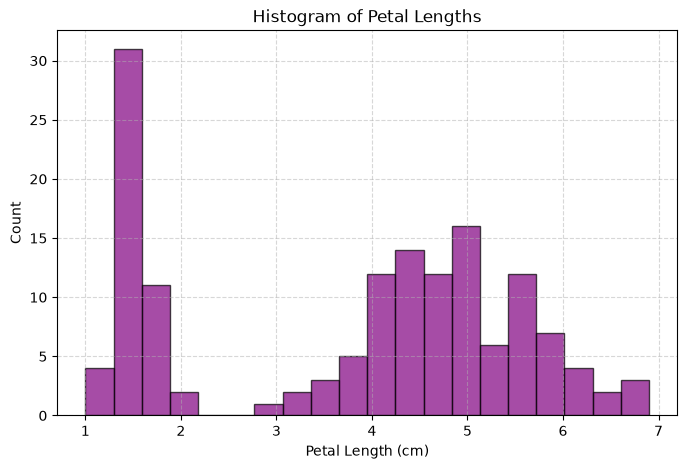

In [34]:
# 4.Data Visualizations (Plots & Charts)

# WHY: Visualizing data distributions with a histogram helps identify patterns, 
# skewness, or clusters (like separate species groups) that summary averages conceal.

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('iris_cleaned.csv')

plt.figure(figsize=(8, 5))
# Plot a histogram showing the distribution frequency of petal lengths
df['petal_length'].plot(
    kind='hist', 
    bins=20, 
    color='purple', 
    edgecolor='black', 
    alpha=0.7
)
plt.title('Histogram of Petal Lengths')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

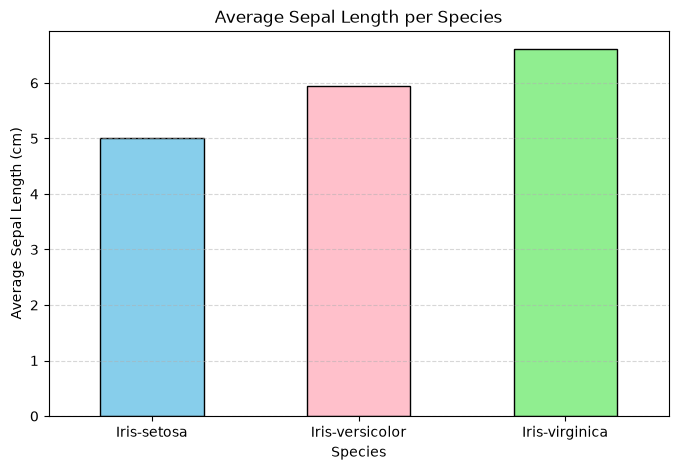

In [35]:
# WHY: Bar charts provide a clear, immediate visual comparison of average metric 
# values across discrete categories (species) for presentations and reports.

species_averages = df.groupby('species').mean()

plt.figure(figsize=(8, 5))
# Create a bar chart comparing average sepal length across species
species_averages['sepal_length'].plot(
    kind='bar', 
    color=['skyblue', 'pink', 'lightgreen'],
    edgecolor='black'
)
plt.title('Average Sepal Length per Species')
plt.xlabel('Species')
plt.ylabel('Average Sepal Length (cm)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

<Figure size 800x500 with 0 Axes>

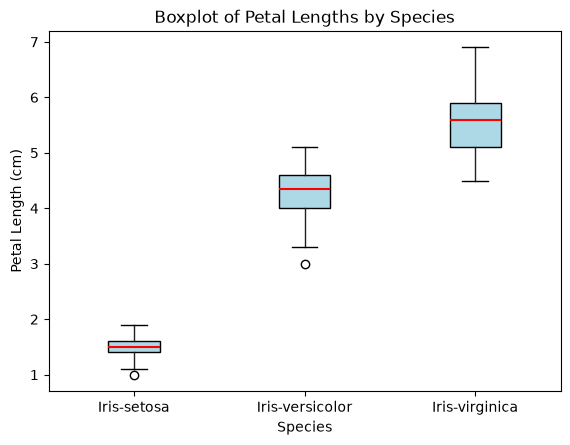

In [36]:
# WHY: Boxplots summarize data distribution spread (median, quartiles, and potential 
# outliers) compactly, making group-to-group comparisons straightforward.

plt.figure(figsize=(8, 5))

# Generate a boxplot to view data spread, medians, and outliers across species
df.boxplot(
    column='petal_length', 
    by='species', 
    grid=False,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue', color='black'),
    medianprops=dict(color='red', linewidth=1.5)
)

plt.title('Boxplot of Petal Lengths by Species')
plt.suptitle('')  # Suppress default pandas multi-index suptitle
plt.xlabel('Species')
plt.ylabel('Petal Length (cm)')
plt.show()

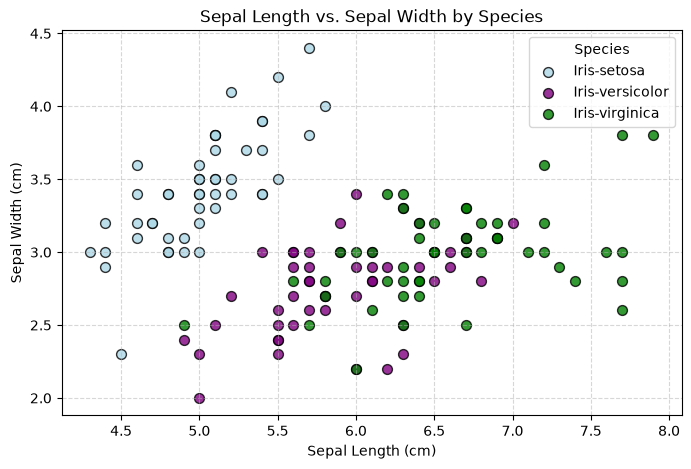

In [38]:
# WHY: Making a scatter plot lets us see if two measurements are related 
# (like checking if a longer sepal usually means a longer petal) by putting a dot for each flower.

plt.figure(figsize=(8, 5))

colors_dict = {'Iris-setosa': 'lightblue', 'Iris-versicolor': 'purple', 'Iris-virginica': 'green'}

# Iterate through each species group to plot points with distinct colors
for species, group in df.groupby('species'):
    plt.scatter(
        group['sepal_length'], 
        group['sepal_width'], 
        label=species, 
        alpha=0.8, 
        color=colors_dict.get(species, 'gray'),  # <-- This line applies your custom colors!
        edgecolors='black', 
        s=50
    )

plt.title('Sepal Length vs. Sepal Width by Species')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.legend(title='Species')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 5.Answers to Analysis Questions

1).Which species has the smallest range of petal lengths?

    -Iris-setosa has the smallest range, with petal lengths tightly grouped around 1.0 to 1.9 cm.
<br>
2). Which species shows the largest spread in petal length values?

    -Iris-virginica and versicolor show the largest overall spread in petal length values.
<br>
3). How do the medians of the three species compare? What does this suggest about their flower sizes?

    -Setosa has the lowest median (~1.5 cm), Versicolor sits in the middle (~4.35 cm), and Virginica has the highest median (~5.55 cm). This demonstrates that Iris-setosa flowers are distinctly smaller in petal size compared to the other two species.
<br>
4). Do sepal length and sepal width appear strongly correlated? Explain why or why not using evidence from a scatter plot.

    -No, they are not strongly correlated overall. On the scatter plot, the data points do not form a single linear pattern across all species.
<br>
5). Based on the scatter, boxplot, and histogram, which flower features seem most useful for separating the species?

    -Petal length and petal width are the most useful features because their boxplots and distributions show clear, distinct separation with minimal overlap between species.